# Base learners

A base learner fits a candidate update to the current negative gradient.
Each formula term specifies one candidate, and `+` lets candidates compete:
`bols(x) + bbs(z)` offers a straight-line update in `x` and a smooth update
in `z`. Each iteration selects the better-fitting update and adds a
`nu`-scaled fraction to the predictor. The table lists the effect shapes
and their main arguments; differences from R `mboost` are described with the
individual learners.

```{list-table}
:header-rows: 1

* - Term
  - Effect
  - Key arguments
* - `bols(x)`
  - Linear / ordinary least squares (optionally a group/factor)
  - `intercept`, `df`, `lambda`
* - `bbs(x)`
  - Penalized B-spline (P-spline), smooth nonlinear
  - `knots`, `degree`, `differences`, `df`
* - `bmono(x)`
  - Monotone (or convex/concave) P-spline
  - `constraint`, `df`
* - `bns(x)`
  - B-spline with an identity ridge penalty (= `bbs` with `differences=0`)
  - `knots`, `df`
* - `bconstrained(x, C=)` via `env=`
  - P-spline with a user-supplied linear constraint $C\beta \ge 0$
  - `C`, `df`, `type`
* - `bspatial(x1, x2)`
  - Tensor-product P-spline surface (2-D smooth)
  - `knots`, `df`
* - `brad(x1, x2, ...)`
  - Radial-basis (Matérn) surface over two or more coordinates
  - `knots`, `df`
* - `bmrf(region)`
  - Markov random field (areal/spatial neighborhoods)
  - `K`, `df`
* - `brandom(g)`
  - Random effect (ridge-penalized factor)
  - `df`
* - `btree(x, ...)`
  - Tree stump(s) — captures interactions / nonlinearity
  - `maxdepth`
* - `bkernel(x)`
  - Kernel ridge regression on one predictor (R `mboost`'s `bkernel` is a different construction, for sets of genetic markers)
  - `bandwidth`
* - `buser(custom, X=, K=, df=4)` via `env=`
  - User-supplied design and penalty, supplied through the `env=` dict
  - `X`, `K`, `df`
```

In [1]:
import numpy as np
import mboostrs as mb
rng = np.random.default_rng(7)

## Formula notation

`mboostrs` uses R-style **formula strings** to specify the model structure. If you
are coming from scikit-learn (where you pass `X` and `y` arrays) or from
statsmodels (which uses a different formula implementation), this section
explains the conventions.

### The `~` operator

A formula has the form `response ~ terms`. The tilde (`~`) separates the
left-hand side (the response variable) from the right-hand side (the
predictor terms). For example:

```
y ~ bbs(x1) + bols(x2)
```

means: model `y` using a P-spline smooth of `x1` plus a linear effect of
`x2`. The `+` operator combines terms additively — just like in R.

### Term syntax

Each term on the right-hand side is a **base-learner call**:

```
learner_name(variable, key=value, ...)
```

The variable name must match a key in the `data` dict. Named arguments
control the learner's behavior (smoothing, penalties, constraints). Use
Python-style booleans (`True`/`False`) and commas between arguments:

```
bbs(x, knots=20, degree=3, df=4)
bmono(x, constraint='increasing', df=4)
btree(x1, x2, maxdepth=2)
```

For `bspatial` the syntax takes two variables separated by a comma:

```
bspatial(x1, x2, df=8)
```

Both `btree` and `bspatial` accept multiple positional variable arguments.

### Interactions and transforms

Unlike R's `model.matrix`, the formula does **not** automatically expand
interactions (`x1:x2`), polynomials (`I(x^2)`), or nested effects. Every term
must be an explicit base-learner call. Inline transforms of a column, such as `log(x)` or `I(x^2)`, are accepted
inside a learner call or as a bare term. A bare variable name (e.g., `y ~ x`)
is shorthand for `y ~ bbs(x)` under `gamboost` and `y ~ bols(x)` under
`glmboost` — i.e. each fitting function's default learner. Use `bols(x)` (in
`gamboost`) or `bbs(x)` (in `glmboost`) if you want the other one.

### The `by=` argument

Any linear learner accepts `by=z`, which multiplies the design by the
observation-specific scalar `z`. This implements varying-coefficient effects
(see [bols(x, by=z)](#varying-coefficient-terms) below).

### The `data` argument

Variables referenced in the formula are looked up from the `data` argument,
which is a Python `dict` of `{name: array}` pairs:

```python
data = {"x": x_array, "y": y_array}
mb.gamboost("y ~ bbs(x, df=4)", data=data, family=mb.Gaussian())
```

The formula string identifies which arrays to use; the `data` dict supplies
their values. This is analogous to R's `data.frame` argument, but the
container is a plain dict.

### Survival responses

For survival families, the left-hand side uses `Surv(time, status)`, where
`status` is 1 for an observed event and 0 for a censored time:

```
Surv(time, status) ~ bbs(age) + bols(sex)
```

### Matrix-valued arguments

Some learners need matrix arguments that cannot be expressed in a string:
`bmrf` (needs a graph-Laplacian `K`), `bconstrained` (needs a constraint matrix
`C`), and `buser` (needs design `X` and penalty `K`). The formula parser
creates placeholder objects; you supply the actual matrices via the
`env=` parameter of `gamboost()`, as described in
[Matrix-backed learners](#matrix-configuration-via-env).

### Differences from R `mboost` formulas

The learner calls and their argument names follow R `mboost`. The
differences are:

- boolean arguments accept either Python capitalization (`True`/`False`) or
  R capitalization (`TRUE`/`FALSE`);
- interactions (`x1:x2`, `x1*x2`) and `poly()` are not expanded; an
  interaction is written as a learner, such as `btree(x1, x2)`,
  `bols(x, by=z)` or the `%X%` operator described in [](real_data.ipynb);
- matrices are passed through `env=` rather than read from the calling
  environment.

[](real_data.ipynb) lists the further formula operators (`.`, term removal,
`%X%`) and the cases the parser rejects.

```{seealso}
[](../methodology/base_learners) for the mathematics behind each learner;
[](../methodology/penalties_df) for how the `df` argument maps to a penalty.
```

## Smooth terms: `bbs`

A P-spline is a B-spline basis with a difference penalty on adjacent
coefficients. The penalty's order (`differences`, default 2) determines what
shape the spline shrinks toward when $\lambda$ is large: a second-order
penalty shrinks toward a straight line (constant and linear functions are
unpenalized), so increasing $\lambda$ makes the fit progressively more linear.

The `df` argument sets the effective degrees of freedom — the fitting code
solves for $\lambda$ so that $\mathrm{df}(\lambda) = \mathrm{df}^\star$
(see [](../methodology/penalties_df) for the derivation). The default
`df=4` gives enough flexibility for smooth nonlinear effects while keeping
overfitting in check.

```{seealso}
[](../methodology/base_learners) §`bbs` — P-spline for the mathematical
definition of the difference penalty and the null-space structure.
```

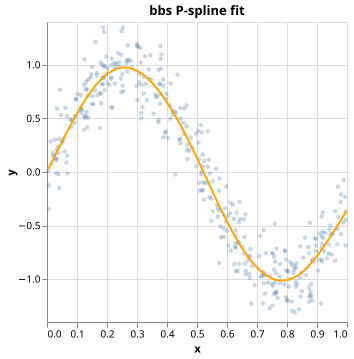

In [2]:
n = 400
x = rng.uniform(0, 1, n)
y = np.sin(6 * x) + rng.normal(scale=0.2, size=n)
m = mb.gamboost("y ~ bbs(x, knots=20, df=4)", data={"x": x, "y": y},
                family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
o = np.argsort(x)
import polars as pl
import altair as alt
pts = alt.Chart(pl.DataFrame({"x": x, "y": y})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
line = alt.Chart(pl.DataFrame({"x": x[o], "y": m.predict()[o]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(pts + line).properties(title="bbs P-spline fit")

## Monotone smooths: `bmono`

When you know an effect is monotone (or convex, concave), `bmono` enforces
the shape restriction on the P-spline. Like `bbs`, it builds a B-spline
basis with a difference penalty, but adds a constraint: the fitted
coefficients must satisfy $C\beta \ge 0$, where $C$ is a first-difference
matrix (for monotonicity) or a second-difference matrix (for convexity).

Two solvers are available. The default **`quad.prog`** solver, which is also
`mboost`'s default, solves each step's penalized least-squares problem under
the constraint exactly (it is a quadratic program, solved by an active-set
method that tracks which constraints hold with equality), so the constraint
holds at every iteration count. The **iterative** solver penalizes constraint
violations with a large $\lambda_2$ and iterates until the violations are
small. It is faster: 1000 iterations on $n=600$ take 8 ms against 282 ms for
`quad.prog`. The violation it leaves has a consistent sign, so a long boosting
path accumulates it rather than averaging it away.

Because the constraint removes directions the spline could otherwise
travel in, a `bmono` fit is typically smoother than an unconstrained `bbs`
at the same `df`.

```{seealso}
[](../methodology/base_learners) §`bmono` — monotone/shape-constrained
P-spline for the iterative and QP solver algorithms; §Shape-constrained
solvers for the penalized objective with the violation penalty $\lambda_2$.
```

prediction is non-decreasing: True


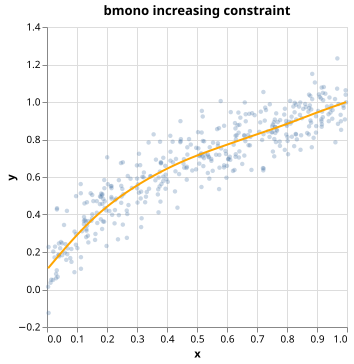

In [3]:
y_mono = np.clip(x, 0, 1) ** 0.5 + rng.normal(scale=0.1, size=n)
m_inc = mb.gamboost("y ~ bmono(x, constraint='increasing', df=4)",
                    data={"x": x, "y": y_mono}, family=mb.Gaussian(),
                    control=mb.boost_control(200, 0.1))
pred = m_inc.predict()[o]
print("prediction is non-decreasing:", bool(np.all(np.diff(pred) >= -1e-8)))
_o = np.argsort(x)
_pts = alt.Chart(pl.DataFrame({"x": x, "y": y_mono})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
_line = alt.Chart(pl.DataFrame({"x": x[_o], "y": m_inc.predict()[_o]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(_pts + _line).properties(title="bmono increasing constraint")

## Random effects: `brandom`

`brandom` models a factor as a ridge-penalized random effect.

Like `bols` on a factor, `brandom` builds an indicator (one-hot) design
matrix with one column per level. The difference is the penalty. `bols` on a
factor is unpenalized by default, so each level gets its own least-squares
effect; a ridge penalty applies only when `df` or `lambda` is given.
`brandom` always applies a ridge penalty (default `df=4`) that shrinks every
level effect toward zero, that is, toward the overall level set by the offset
and the other terms. This borrows strength across levels: a level with little
data is pulled toward the overall level, and a level with much data keeps an
effect close to its own mean.

Use `brandom` instead of `bols` for a factor with more than about 10 levels.
For spatial effects on a factor with a known neighborhood graph, use
`bmrf` instead.

```{seealso}
[](../methodology/base_learners) §Categorical predictors and `brandom`
for the fixed-effects vs. random-effects distinction and the rule of
thumb on when to switch.
```

recovered group means correlate with truth: 1.0


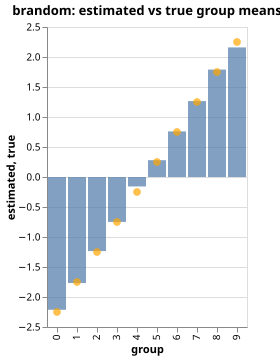

In [4]:
g = rng.integers(0, 10, n).astype(float)
y_re = (g - 4.5) * 0.5 + rng.normal(scale=0.3, size=n)
m_re = mb.gamboost("y ~ brandom(g, df=4)", data={"g": g, "y": y_re},
                   family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
print("recovered group means correlate with truth:",
      round(float(np.corrcoef(m_re.predict(), (g - 4.5) * 0.5)[0, 1]), 3))
_df_g = pl.DataFrame({"group": np.arange(10), "true": (np.arange(10) - 4.5) * 0.5,
                       "estimated": m_re.coef()["g"]})
_bar = alt.Chart(_df_g).mark_bar(opacity=0.7).encode(x="group:O", y="estimated")
_pt = alt.Chart(_df_g).mark_circle(color="orange", size=60).encode(x="group:O", y="true")
(_bar + _pt).properties(title="brandom: estimated vs true group means")

### Longitudinal data

A common application of `brandom` is subject-level random intercepts in
repeated-measures (longitudinal) data:

R^2: 0.935


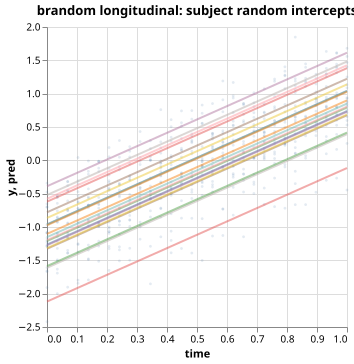

In [5]:
n_subjects = 20
n_per = 30
subject = np.repeat(np.arange(n_subjects), n_per).astype(float)
time = np.tile(np.linspace(0, 1, n_per), n_subjects)
# random intercept per subject + fixed time trend
re_true = np.random.default_rng(0).normal(0, 0.5, n_subjects)
y_long = (time - 0.5) * 2 + re_true[subject.astype(int)] + rng.normal(scale=0.2, size=n_subjects * n_per)
mlong = mb.gamboost("y ~ bols(time) + brandom(subject, df=4)",
                    data={"time": time, "subject": subject, "y": y_long},
                    family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
print("R^2:", round(float(np.corrcoef(y_long, mlong.predict())[0, 1])**2, 3))
_df_long = pl.DataFrame({"time": time, "y": y_long, "pred": mlong.predict(), "s": subject.astype(int)})
_pts_long = alt.Chart(_df_long).mark_circle(size=8, opacity=0.15).encode(x="time", y="y")
_line_long = alt.Chart(_df_long).mark_line(opacity=0.5).encode(x="time", y="pred", detail="s:N", color=alt.Color("s:N", legend=None))
(_pts_long + _line_long).properties(title="brandom longitudinal: subject random intercepts")

## 2-D spatial smooths: `bspatial`

A tensor-product P-spline for two-dimensional spatial or interaction effects.
The basis is the Kronecker product of two marginal B-spline bases,
$X = X_1 \otimes X_2$, with the additive Kronecker penalty
$K_1 \otimes I_2 + I_1 \otimes K_2$. This extends the 1-D P-spline
to a smooth surface over two variables.

`bspatial` defaults to `center=False`, so the surface keeps the
unpenalized part of its penalty, as in R `mboost::bspatial`. Passing `center=True` removes the constant surface from the spline, absorbing
it into the model intercept, and eliminates the null space of the penalty.
Use `center=True` when the surface is poorly conditioned or when you need a
`df` below the null-space dimension, `differences ** 2` (4 by default). Centering changes the fitted surface, so the two settings can reach
different risks on the same data.

When the location effect is patchy (the response changes between regions
with sharp edges, such as flood zones or river bends) or has boundaries,
compare `btree(x1, x2, maxdepth=3)` with `bspatial(x1, x2)` on held-out
risk. The tree places cut points on both coordinates and fits the regions
directly; the surface smooths across their edges. A default `btree` is a
stump, which splits on one coordinate per boosting step, so the depth is set
here. `autospec`, the automatic specification search
([](specification_search.ipynb)), makes this comparison when given a positive
fit budget and records it in the report of the recommendation it returns,
`rec.report()`.

```{seealso}
[](../methodology/base_learners) §`bspatial` — tensor-product P-spline for
the Kronecker construction and what centering does to the penalty.
```

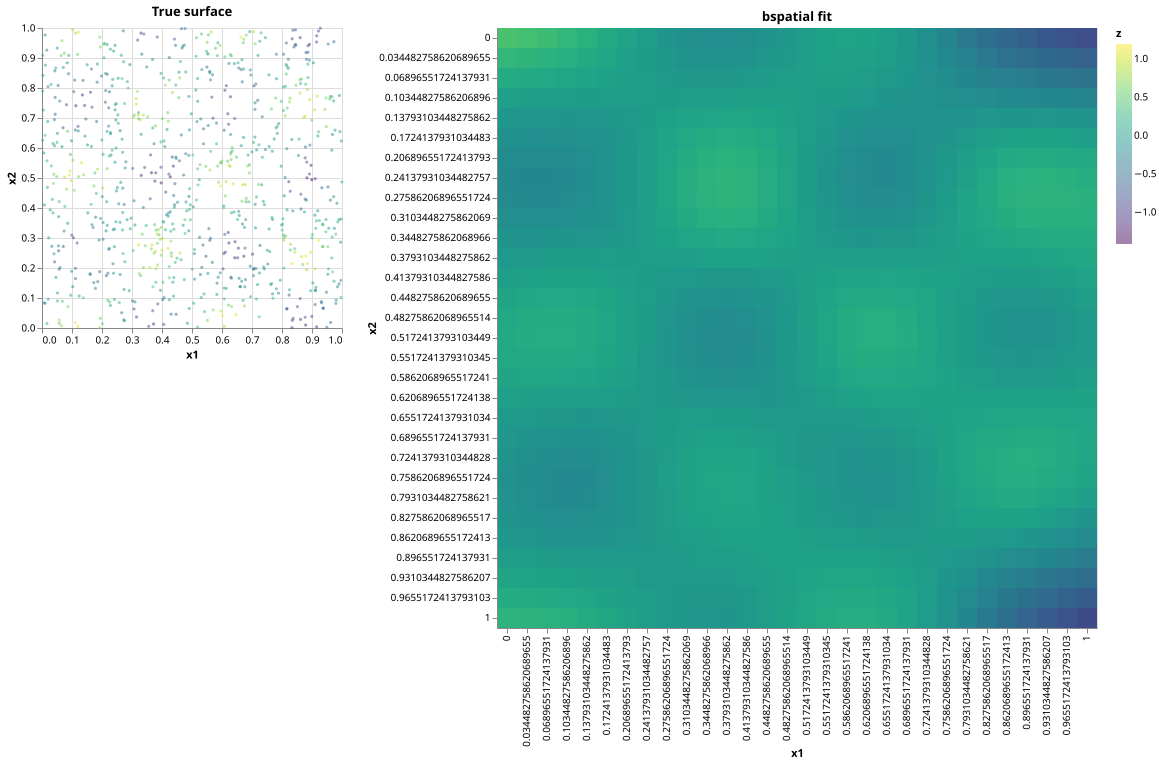

In [6]:
n = 800
x1 = rng.uniform(0, 1, n); x2 = rng.uniform(0, 1, n)
z = np.sin(4 * np.pi * x1) * np.cos(4 * np.pi * x2) + rng.normal(scale=0.2, size=n)
m_sp = mb.gamboost(
    "z ~ bspatial(x1, x2, df=8)",
    data={"x1": x1, "x2": x2, "z": z},
    family=mb.Gaussian(), control=mb.boost_control(mstop=300, nu=0.1),
)
g = np.linspace(0, 1, 30); gx1, gx2 = np.meshgrid(g, g)
z_hat = m_sp.predict(newdata={"x1": gx1.ravel(), "x2": gx2.ravel()}).reshape(30, 30)
import polars as pl
import altair as alt
df_true = pl.DataFrame({"x1": x1, "x2": x2, "z": z})
df_hat = pl.DataFrame({"x1": gx1.ravel(), "x2": gx2.ravel(), "z": z_hat.ravel()})
c1 = alt.Chart(df_true).mark_circle(size=10, opacity=0.5).encode(
    x="x1", y="x2", color=alt.Color("z", scale=alt.Scale(scheme="viridis"))
).properties(title="True surface")
c2 = alt.Chart(df_hat).mark_rect().encode(
    x="x1:O", y="x2:O", color=alt.Color("z:Q", scale=alt.Scale(scheme="viridis"))
).properties(title="bspatial fit")
alt.hconcat(c1, c2)

## Radial basis surfaces: `brad`

`brad` fits a smooth surface from scattered points rather than from a grid.
It places a set of centres over the predictor space, measures the Matérn
covariance from every observation to every centre, and whitens the result by
the centres' own covariance so a plain ridge penalty applies:

$$X = C(x, \text{centres})\, C(\text{centres}, \text{centres})^{-1/2},
\qquad K = I.$$

The Matérn at smoothness $3/2$ is

$$C(d) = \left(1 + \tfrac{\sqrt{3}\,d}{\theta}\right)
          \exp\!\left(-\tfrac{\sqrt{3}\,d}{\theta}\right),$$

where $d$ is the distance between two points and $\theta$ is a range
parameter. The default $\theta$ makes correlation at the training data diameter equal
to $10^{-3}$.

Use it instead of `bspatial` when the predictors are scattered rather than
gridded, or when you want a smooth over three or more coordinates — a
tensor-product basis grows as the product of its marginals, while `brad` grows
only with the number of centres you ask for.

Because the whitened design with $K = I$ is an ordinary penalized linear
smoother, `brad` is fitted as a user-supplied design-and-penalty block, and
everything that works for `buser` works for `brad`: cross-validation,
stability selection and prediction on new data.

```{note}
`brad` places its centres by greedy farthest-point selection, where
`mboost::brad` uses `fields::cover.design`, a swapping optimiser. Both are
space-filling and neither is canonical, so a `brad` fit here is comparable to R
`mboost`'s but not identical to it. The covariance itself is the same Matérn.
```

The Python formula spelling is `y ~ brad(x1, x2, knots=40, df=4)`. The
`Brad` constructor also accepts training data and can be supplied through
`learners=`, as below. Both routes retain the training centres, range and
whitening matrix. `predict(newdata)` rebuilds the design from coordinate
columns automatically; `radial.design(newdata)` exposes that same design
for a direct matrix comparison. Weighted centering and `by=` multipliers
are applied by the fitting and prediction engine.


centres: 40  theta: 0.2496
correlation with the true surface: 0.949


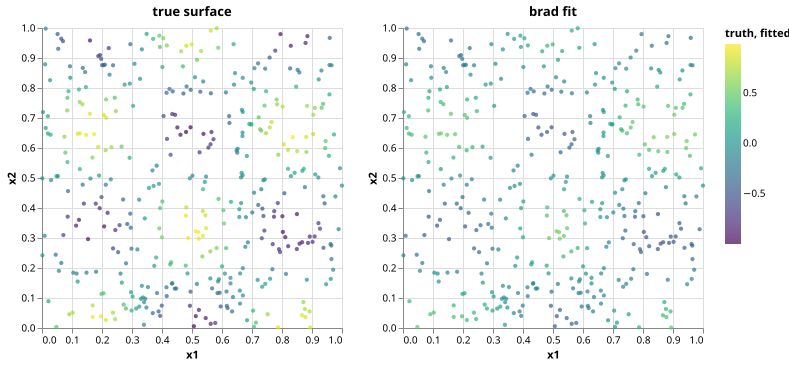

In [7]:
rng_brad = np.random.default_rng(3)
n_brad = 400
x1_brad = rng_brad.uniform(0, 1, n_brad)
x2_brad = rng_brad.uniform(0, 1, n_brad)
surface = np.sin(3 * np.pi * x1_brad) * np.cos(3 * np.pi * x2_brad)
data_brad = {"x1": x1_brad, "x2": x2_brad, "y": surface + rng_brad.normal(0, 0.2, n_brad)}

radial = mb.Brad(["x1", "x2"], data_brad, knots=40, df=4)
m_brad = mb.gamboost(
    "y ~ bols(x1)",            # the formula still names a term; `learners=` supplies the real one
    data=data_brad,
    family=mb.Gaussian(),
    learners=[radial],
    control=mb.boost_control(300, 0.1),
)
new_locations = {"x1": np.linspace(0, 1, 10), "x2": np.full(10, 0.5)}
new_predictions = m_brad.predict(new_locations, type="response")
fitted_brad = np.asarray(m_brad.fitted_).ravel()
print("centres:", radial.centres.shape[0], " theta:", round(radial.theta, 4))
print("correlation with the true surface:", round(float(np.corrcoef(fitted_brad, surface)[0, 1]), 4))

_grid = pl.DataFrame({"x1": x1_brad, "x2": x2_brad, "fitted": fitted_brad, "truth": surface})
alt.hconcat(
    alt.Chart(_grid).mark_circle(size=18).encode(
        x="x1", y="x2", color=alt.Color("truth", scale=alt.Scale(scheme="viridis"))
    ).properties(title="true surface"),
    alt.Chart(_grid).mark_circle(size=18).encode(
        x="x1", y="x2", color=alt.Color("fitted", scale=alt.Scale(scheme="viridis"))
    ).properties(title="brad fit"),
)

In R, `brad` is ordinary formula syntax:

```r
set.seed(3)
n <- 400
d <- data.frame(x1 = runif(n), x2 = runif(n))
d$y <- sin(3 * pi * d$x1) * cos(3 * pi * d$x2) + rnorm(n, sd = 0.2)

m_brad <- gamboost(y ~ brad(x1, x2, knots = 40, df = 4), data = d,
                   control = boost_control(mstop = 300, nu = 0.1))
cor(fitted(m_brad), sin(3 * pi * d$x1) * cos(3 * pi * d$x2))
```


## Trees: `btree`

A tree base learner fits a piecewise constant function by splitting the
predictor space into regions.

`btree` fits a shallow regression tree (default depth 1, a stump) to the
pseudo-residual at each boosting step: it chooses split points from the data
and fits a constant in each region. The other learners fit a fixed design
matrix with a penalty, so `df` sets their flexibility; a tree's flexibility is
set by its depth, and `btree` takes no `df`. AIC counts a tree step's degrees
of freedom given the partition it chose, so the count omits the search over
split points and understates the tree's flexibility.
Use it when the effect is discontinuous, involves interactions between
covariates, or has a shape that splines cannot easily represent.

`btree(x, x2, maxdepth=2, selection=sse)` makes one joint tree: each split
can use either column, and a depth of at least two permits an interaction.
`btree(x) + btree(x2)` gives an additive model of separate trees; the default
`maxdepth=1` fits stumps even when several columns are supplied. Write
`btree(., maxdepth=6, selection=sse)` for one tree over all predictors in the
data. These formulas predict at new rows through the named input columns.

`selection=sse`, the default, searches the splits on all columns for the
largest reduction in squared error. It can find a boundary whose marginal
association is weak -- on the California housing data a joint depth-6 tree
reaches 0.2638 log-RMSE with `sse` against 0.2705 with `ctree` -- but it
favours columns with many possible splits. `selection=ctree` chooses the
column by its association with the gradient before choosing the split; it
is more conservative with noisy, mixed-type columns, and matches R mboost's
`btree`. Tune tree depth and the stopping iteration on held-out rows.

For Gaussian responses and a fit budget, `autospec` also compares joint CART
trees of depths 3 and 6 when undeclared continuous predictors include a
coordinate-like pair such as
`lon` and `lat`. The joint tree replaces the terms the user did not declare
only if it lowers the held-out risk, computed on the same folds for both
candidates, by at least 2%; declared terms remain. Supply spatial
folds when predictions must transfer to new regions: random row folds measure
prediction near locations already represented in training. Inspect
`rec.evidence["joint_tree"]`; use `joint_tree=False` to keep an additive
search. Evaluate the selected specification on data
held out of the search.

```{seealso}
[](../methodology/base_learners) §`btree` — decision tree for why it
falls outside the linear-smoother framework.
```

tree model train RMSE: 0.161


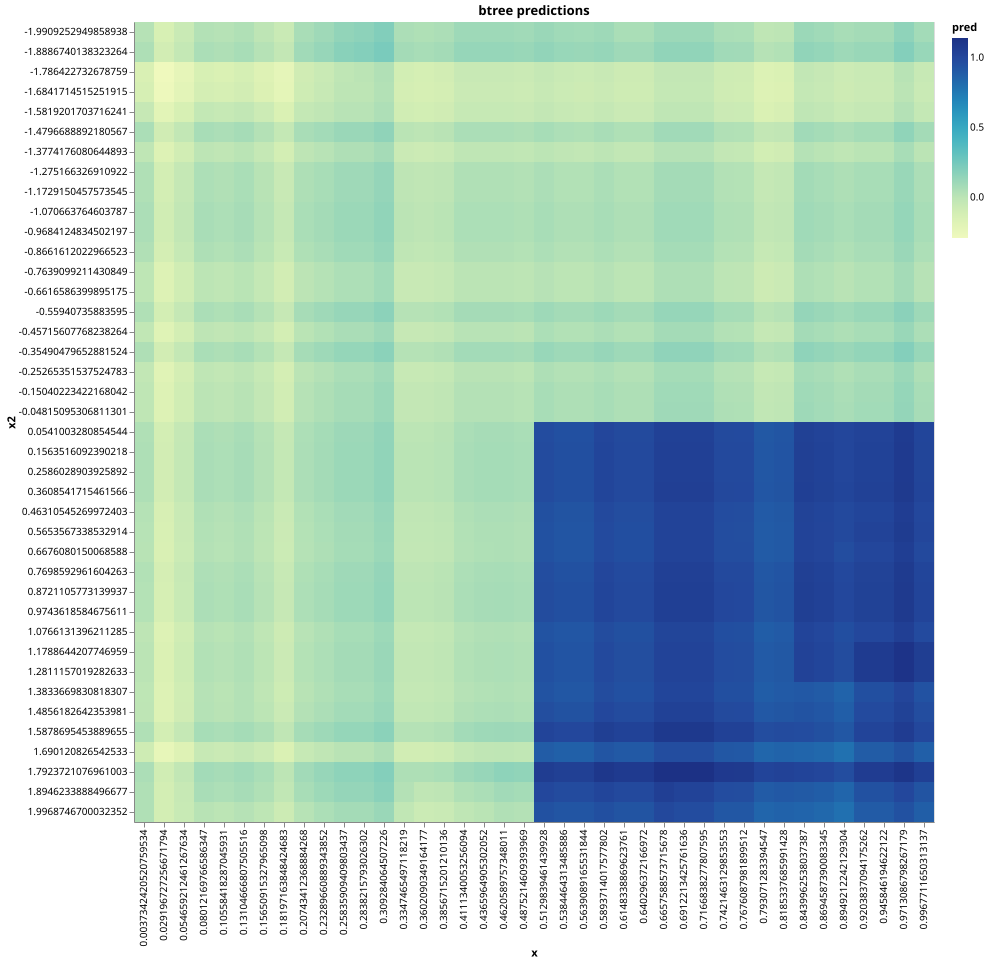

In [8]:
# Two successive splits represent the rectangular step in the mean.
n = 400
x2 = rng.uniform(-2, 2, n)
y_tree = ((x > 0.5) & (x2 > 0)).astype(float) + rng.normal(scale=0.2, size=n)
m_tree = mb.gamboost("y ~ btree(x, x2, maxdepth=2, selection=sse)", data={"x": x, "x2": x2, "y": y_tree},
                     family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
print("tree model train RMSE:",
      round(float(np.sqrt(np.mean((m_tree.predict() - y_tree) ** 2))), 3))
_grid = 40
_gx = np.linspace(x.min(), x.max(), _grid)
_gx2 = np.linspace(x2.min(), x2.max(), _grid)
_ggx, _ggx2 = np.meshgrid(_gx, _gx2)
_z = m_tree.predict(newdata={"x": _ggx.ravel(), "x2": _ggx2.ravel()}).reshape(_grid, _grid)
_df_btree = pl.DataFrame({"x": _ggx.ravel(), "x2": _ggx2.ravel(), "pred": _z.ravel()})
alt.Chart(_df_btree).mark_rect().encode(x="x:O", y="x2:O", color="pred:Q").properties(title="btree predictions")

### Tree partition: `plot_btree_partition`

`btree(x, x2, maxdepth=2)` fits one joint tree. `plot_btree_partition`
draws its fitted contribution as a heatmap with the `btree_splits()`
cutpoints overlaid as rules, and `btree_partition_table` returns the same
regions as a Polars frame -- one row per leaf, with the contribution at
each region's centre. A one-column tree falls back to a step plot; a tree
over more than two columns takes `at=` to fix the columns not drawn.


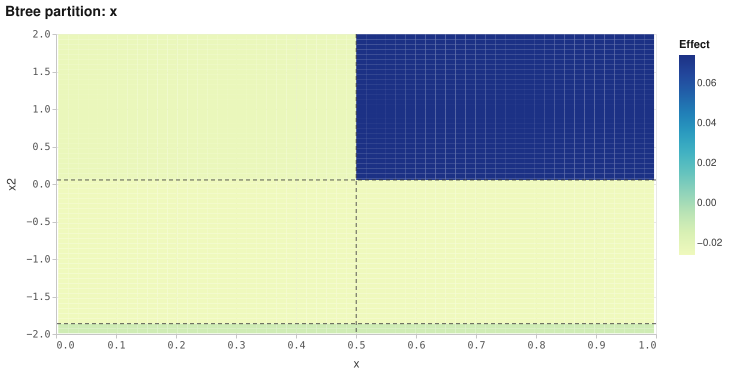

In [9]:
# A single boosting step fits one tree, so the partition is that tree.
m_part = mb.gamboost("y ~ btree(x, x2, maxdepth=2, selection=sse)",
                     data={"x": x, "x2": x2, "y": y_tree},
                     family=mb.Gaussian(), control=mb.boost_control(1, 0.1))
m_part.plot_btree_partition()

In [10]:
m_part.btree_partition_table()

x_lower,x_upper,x2_lower,x2_upper,value
f64,f64,f64,f64,f64
0.003734,0.996771,-1.990925,-1.862132,-0.012123
0.003734,0.996771,-1.862132,0.053942,-0.026107
0.003734,0.500361,0.053942,1.996875,-0.023739
0.500361,0.996771,0.053942,1.996875,0.074089


(varying-coefficient-terms)=
## Varying-coefficient terms: `bols(x, by=z)`

The `by` argument turns a linear term into a varying-coefficient model: the
effect of `x` varies linearly with `z`. This is the boosting equivalent of
$x \times z$ interaction.

Mechanically, the whole design is multiplied element-wise by `z`:
$X_{\text{by}}[i, j] = z_i \cdot X[i, j]$. When $z \in \{0, 1\}$
the effect selects a subgroup; when $z$ is continuous the coefficient of
`x` varies proportionally with `z`. Any linear learner (`bols`, `bbs`,
`bmono`, etc.) accepts the `by=` argument.

The intercept column is multiplied too, so `bols(x, by=z)` fits
$z\,(\beta_0 + \beta_1 x)$ and the term carries the main effect of `z` along
with the interaction. `bols(x, by=z, intercept=False)` fits $\beta_1 x z$
alone, which is the spelling to use when `z` already has its own term.

For survival responses, do not use observed event/censoring time as this
modifier: a time-dependent effect requires start-stop risk sets (each subject
contributes one row per interval during which its covariates are constant),
which the survival families do not implement.

### A factor `by=`

A factor has no single column to multiply by. R's answer, which `gamboost`
follows, is to code it with treatment contrasts and stack one copy of the
design per non-reference level, penalized block by block. `bbs(x, by=g)` with
a four-level `g` is therefore three copies of the B-spline basis: the first
level is the reference, its curve is zero for this term, and each other level
fits its difference from it. A level's own curve comes from adding a main
effect, as in `bbs(x, df=4) + bbs(x, by=g, df=10)`.

Two consequences follow from the stacking. The `df` covers the whole stacked
design rather than one block, so it has to be at least
`differences * (levels - 1)` — 6 for a four-level factor at the default second
differences — and a smaller value is rejected. And the term is one learner:
component-wise boosting selects or rejects all the level blocks together.

`gamboost` builds this for `bols` and `bbs`, in Python and in R. `glmboost`
and the LSS frontends do not, and refuse a factor `by=` rather than encoding
the levels as numbers.

```{seealso}
[](../methodology/base_learners) §Varying-coefficient effects for the
mathematical formulation of the `by` multiplication.
```

R^2: 0.689


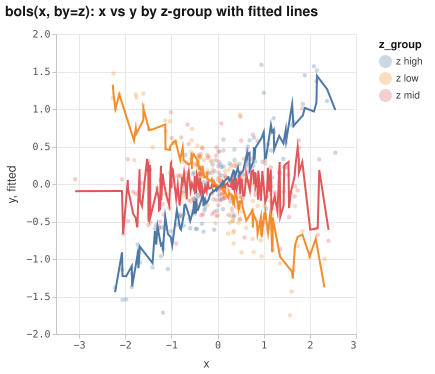

In [11]:
n = 400
x_b = rng.normal(size=n)
z_b = rng.uniform(-1, 1, n)
y_b = 0.8 * z_b * x_b + rng.normal(scale=0.3, size=n)
m_by = mb.gamboost("y ~ bols(x, by=z)", data={"x": x_b, "z": z_b, "y": y_b},
                   family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
print(f"R^2: {np.corrcoef(y_b, m_by.predict())[0, 1]**2:.3f}")
z_groups = np.select(
    [z_b < -0.4, z_b <= 0.4], ["z low", "z mid"], default="z high"
)
_df_by = pl.DataFrame({"x": x_b, "z": z_b, "y": y_b, "fitted": m_by.predict(), "z_group": z_groups})
pts = alt.Chart(_df_by).mark_circle(size=20, opacity=0.3).encode(
    x="x", y="y", color="z_group:N")
line = alt.Chart(_df_by).mark_line(strokeWidth=2).encode(
    x="x", y="fitted", color="z_group:N", detail="z_group:N")
(pts + line).properties(title="bols(x, by=z): x vs y by z-group with fitted lines")

The fitted model recovers a coefficient of `x` that depends on `z`; the
`by=z` argument supplies the interaction.

## Ridge-penalized B-splines: `bns`

`bns` fits a B-spline basis with a ridge penalty, equivalent to `bbs` with
`differences=0` (a ridge penalty on the basis coefficients). Unlike a true
natural cubic spline, `bns` does not impose boundary-knot linearity — it
retains the full B-spline basis and substitutes an identity ($K = I$) penalty
for the difference penalty.

`bns` differs from `bbs` in the penalty: a ridge ($K = I$) penalizes
*all* directions equally. There is no null space,
so the minimum attainable $\mathrm{df}$ is 0 — the entire curve can be
shrunk to zero. By contrast, `bbs` with the default second-order difference
penalty has a 2-dimensional null space (constant + linear) and cannot
shrink below $\mathrm{df} = 2$. Use `bns` when you want the spline to be
able to vanish entirely (no null space). Boundary behavior is unchanged
from `bbs` — `bns` inherits the standard B-spline basis without a natural-
spline constraint.

```{seealso}
[](../methodology/base_learners) §`bns` — ridge-penalized B-spline for the
null-space comparison with `bbs`.
```

R^2: 0.836


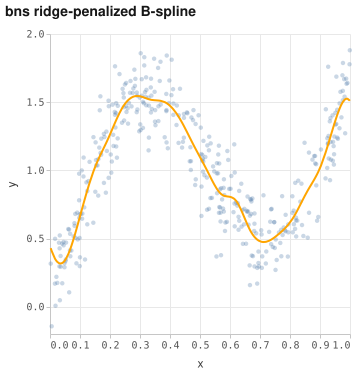

In [12]:
n = 400
x_ns = rng.uniform(0, 1, n)
y_ns = 2 * x_ns + np.sin(6 * x_ns) + rng.normal(scale=0.2, size=n)
m_ns = mb.gamboost("y ~ bns(x, df=5)", data={"x": x_ns, "y": y_ns},
                   family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
print(f"R^2: {np.corrcoef(y_ns, m_ns.predict())[0, 1]**2:.3f}")
_o_ns = np.argsort(x_ns)
_pts_ns = alt.Chart(pl.DataFrame({"x": x_ns, "y": y_ns})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
_line_ns = alt.Chart(pl.DataFrame({"x": x_ns[_o_ns], "y": m_ns.predict()[_o_ns]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(_pts_ns + _line_ns).properties(title="bns ridge-penalized B-spline")

## Kernel smoothing: `bkernel`

`bkernel` is a kernel-regression base learner: it centres a kernel (Gaussian,
Epanechnikov, etc.) at each boosting step. The `bandwidth` controls the
smoothing neighborhood size.

Unlike all other learners, `bkernel` builds a dense $n \times n$ kernel
matrix $K[i,j] = k(\|x_i - x_j\| / h)$ and fits a kernel ridge regression.
Memory cost is $O(n^2)$, so it is practical only for moderate sample sizes
(up to a few thousand observations). The `bkernel(x, landmarks = 30)`
Nyström approximation cuts that to $O(n \cdot m)$ against `m` evenly spaced
quantile landmarks of `x` (exact as `m` approaches the number of distinct
observations; Gaussian kernel only). For larger data, `bbs` remains the
default and cheapest smooth.

```{seealso}
[](../methodology/base_learners) §`bkernel` — kernel ridge regression for
the kernel-matrix construction, the $O(n^2)$ cost discussion, and the
Nyström landmark alternative.
```

R^2: 0.938


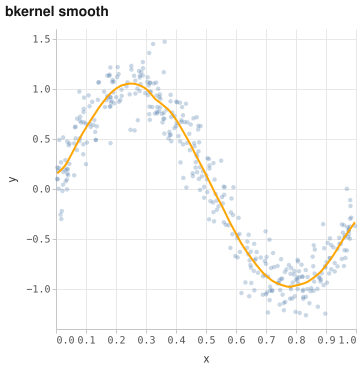

In [13]:
n = 400
x_k = rng.uniform(0, 1, n)
y_k = np.sin(6 * x_k) + rng.normal(scale=0.2, size=n)
m_k = mb.gamboost("y ~ bkernel(x, bandwidth=0.15, kernel='epanechnikov')",
                  data={"x": x_k, "y": y_k}, family=mb.Gaussian(),
                  control=mb.boost_control(200, 0.1))
print(f"R^2: {np.corrcoef(y_k, m_k.predict())[0, 1]**2:.3f}")
_o_k = np.argsort(x_k)
_pts_k = alt.Chart(pl.DataFrame({"x": x_k, "y": y_k})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
_line_k = alt.Chart(pl.DataFrame({"x": x_k[_o_k], "y": m_k.predict()[_o_k]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(_pts_k + _line_k).properties(title="bkernel smooth")

(matrix-configuration-via-env)=
## Matrix-backed learners: `bmrf`, `bconstrained`, `buser`

Learners that need a matrix (`bmrf`, `bconstrained`, `buser`) read it from the
`env=` dict. The figure traces formula terms and programmatic learner
specifications to the Rust core. The `bmrf` example fits four regions on a
line, with the penalty matrix `K` of the adjacency graph supplied through
`env=`.

```{figure} ../figures/mermaid-60155561883b.svg
:name: mermaid-60155561883b
:alt: Formula and programmatic learner inputs converge at the gamboost learner interface and then enter Rust learner setup.

Formula terms and programmatic learner specifications are normalized before the Rust core prepares their design and penalty structures.
```


fitted regions: [ 0.069  1.507 -1.988  0.027]


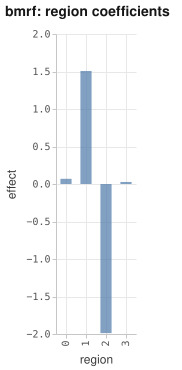

In [14]:

# 4 regions in a linear adjacency graph (0-1-2-3)
K = np.array([
    [ 1, -1,  0,  0],
    [-1,  2, -1,  0],
    [ 0, -1,  2, -1],
    [ 0,  0, -1,  1],
], dtype=float)

n_mrf = 100
regions = rng.choice(4, size=n_mrf).astype(float)
y_mrf = 1.5 * (regions == 1) - 2.0 * (regions == 2) + rng.normal(scale=0.3, size=n_mrf)

m_mrf = mb.gamboost(
    "y ~ bmrf(regions, K=K_mrf, df=4)",
    data={"regions": regions, "y": y_mrf},
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
    env={"K_mrf": K},
)
print("fitted regions:", np.round(m_mrf.coef()["regions"][:4], 3))
_df_mrf = pl.DataFrame({"region": np.arange(4), "effect": m_mrf.coef()["regions"]})
alt.Chart(_df_mrf).mark_bar(opacity=0.7).encode(x="region:O", y="effect:Q").properties(title="bmrf: region coefficients")

### Shape constraints: `bconstrained`

`bconstrained` is a generalization of `bmono` that accepts an arbitrary
constraint matrix $C$ such that $C\beta \ge 0$. For monotonicity, $C$ is
the first-difference matrix; for convexity, the second-difference matrix;
for any other shape restriction, you supply $C$ directly.

The column count of $C$ must match the B-spline basis dimension
$p = n_{\text{inner}} + \text{degree} + 1$ (24 under the defaults:
`knots=20`, `degree=3`). It uses the same solvers as `bmono`: the exact
`quad.prog` by default, or `type="iterative"`.

**The `C` matrix cannot be expressed in a formula string.** Supply it
via the `env=` parameter: `bconstrained(x, C=C_con, df=4)`.

To enforce monotonicity, use a first-difference matrix
($\beta_{j+1} - \beta_j \ge 0$):

```{seealso}
[](../methodology/base_learners) §`bconstrained` — general linear
constraint P-spline for the relationship to `bmono` and the B-spline
column-count formula.
```

prediction is non-decreasing: True


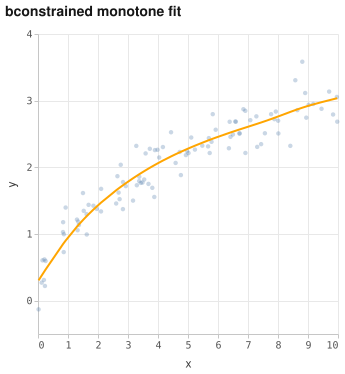

In [15]:

p = 24  # 20 inner knots + degree 3 + 1
C = np.zeros((p - 1, p))
for i in range(p - 1):
    C[i, i] = -1
    C[i, i + 1] = 1

n_con = 100
x_con = rng.uniform(0, 10, n_con)
y_con = np.sqrt(x_con) + rng.normal(scale=0.2, size=n_con)

m_con = mb.gamboost(
    "y ~ bconstrained(x, C=C_con, df=4)",
    data={"x": x_con, "y": y_con},
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
    env={"C_con": C},
)
pred_con = m_con.predict()[np.argsort(x_con)]
print("prediction is non-decreasing:", bool(np.all(np.diff(pred_con) >= -1e-8)))
_o_con = np.argsort(x_con)
_pts_con = alt.Chart(pl.DataFrame({"x": x_con, "y": y_con})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
_line_con = alt.Chart(pl.DataFrame({"x": x_con[_o_con], "y": m_con.predict()[_o_con]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(_pts_con + _line_con).properties(title="bconstrained monotone fit")

### User-supplied designs: `buser`

`buser` takes a design matrix and a penalty matrix that already exist, for
example from another workflow, and wraps the $(X, K)$ pair as a block-linear
learner, equivalent to a `bols` with a user-supplied design and penalty. Use it
when none of the built-in base learners expresses the effect directly, or to
use a design from a different modeling framework.

The penalty $K$ must be square and its dimension must match the column count
of $X$. Shape validation is enforced at construction. The package checks shapes but
cannot tell whether the supplied columns and penalty encode the intended effect.

```{seealso}
[](../methodology/base_learners) §`buser` — user-supplied design and
penalty for the penalized least-squares fit of the block and the
shape-validation rules.
```

custom design coefficients: [ 1.009 -0.81 ]


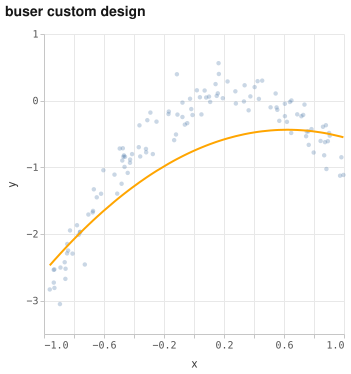

In [16]:

n_user = 120
x_user = rng.uniform(-1, 1, n_user)
X_user = np.column_stack([x_user, x_user**2])
K_user = np.eye(X_user.shape[1])
y_user = 1.0 * x_user - 2.0 * x_user**2 + rng.normal(scale=0.2, size=n_user)

m_user = mb.gamboost(
    "y ~ buser(custom, X=X_basis, K=K_penalty, df=2)",
    data={"y": y_user},
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
    env={"X_basis": X_user, "K_penalty": K_user},
)
print("custom design coefficients:", np.round(m_user.coef()["custom"], 3))
_o_user = np.argsort(x_user)
_pts_user = alt.Chart(pl.DataFrame({"x": x_user, "y": y_user})).mark_circle(size=20, opacity=0.3).encode(x="x", y="y")
_line_user = alt.Chart(pl.DataFrame({"x": x_user[_o_user], "y": m_user.predict()[_o_user]})).mark_line(color="orange", strokeWidth=2).encode(x="x", y="y")
(_pts_user + _line_user).properties(title="buser custom design")

## Weights and offsets

All models accept a `weights` vector to up- or down-weight observations and an
`offset` to shift the additive predictor:

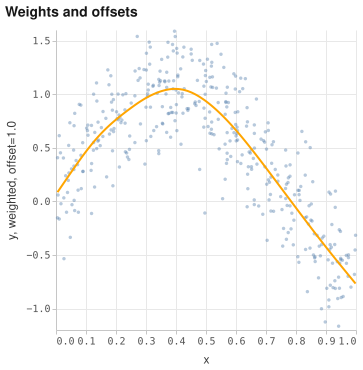

In [17]:
n = 400
x = rng.uniform(0, 1, n)
y = np.sin(4 * x) + rng.normal(scale=0.3, size=n)
w = np.where(x > 0.5, 0.1, 1.0)         # down-weight right half
mw = mb.gamboost("y ~ bbs(x, df=4)", data={"x": x, "y": y},
                 family=mb.Gaussian(), control=mb.boost_control(200, 0.1),
                 weights=w)
mo = mb.gamboost("y ~ bbs(x, df=4)", data={"x": x, "y": y},
                 family=mb.Gaussian(), control=mb.boost_control(200, 0.1),
                 offset=1.0)
import polars as pl
import altair as alt
o = np.argsort(x)
df_pts = pl.DataFrame({"x": x, "y": y})
df_fit = pl.DataFrame({"x": x[o], "weighted": mw.predict()[o], "offset=1.0": mo.predict()[o]})
pts = alt.Chart(df_pts).mark_circle(size=12, opacity=0.4).encode(x="x", y="y")
w_line = alt.Chart(df_fit).mark_line(color="orange", strokeWidth=2).encode(x="x", y="weighted")
o_line = alt.Chart(df_fit).mark_line(color="#0062ff", strokeWidth=2, strokeDash=[4, 3]).encode(x="x", y="offset=1.0")
(pts + w_line + o_line).properties(title="Weights and offsets")

### Integer and fractional weights

A weight of `3` and a weight of `0.1` are read differently, and the difference
changes the fit.

Integer weights are **frequencies**: weight 3 stands for three identical rows,
and the model uses them at that scale. Fractional weights are **analytic
weights**, where only the ratios carry meaning — halving every weight is the
same statement about the data. Because the absolute level is then arbitrary,
`mboostrs` rescales fractional weights to sum to the number of weight-positive
rows before fitting, which is what R `mboost` does in `mboost:::rescale_weights`.
The weights `w` of the example sum to 216.4 over 400 rows, all of them
weight-positive, and are rescaled to sum to exactly 400 before fitting.

That rescaling is visible on the fitted model rather than implied:


In [18]:
print("input weights sum :", round(float(np.asarray(mw.input_weights()).sum()), 4))
print("model weights sum :", round(float(np.asarray(mw.model_weights()).sum()), 4))
print("weight-positive rows:", int((np.asarray(mw.input_weights()) > 0).sum()))
print("policy            :", mw.weight_policy)
print("note              :", mw.weights_note())


input weights sum : 216.4
model weights sum : 400.0
weight-positive rows: 400
policy            : upstream
note              : user weights rescaled to sum to 400 (policy='upstream'; fractional weights are analytic)


`weight_policy=` names the rule instead of leaving it implicit:

| `weight_policy` | Fractional weights | Integer weights |
|---|---|---|
| `"upstream"` (default) | rescaled to sum to the weight-positive row count, matching R `mboost` | used as given |
| `"raw"` | used as given | used as given |

Only the loss scale moves, so the two policies select the same terms in the
same order — but the reported risk differs by the rescaling factor, and so does
anything derived from it. The ratio of the two final risks is exactly the
rescaling factor, $400/216.4 = 1.8484$. Use `"raw"` when the weights already
carry the scale you want the risk reported on, such as sampling weights that
sum to a population total; keep the default when comparing against R.

A zero weight excludes a row while keeping its position, so every row-aligned
object — `fitted()`, `predict()`, residuals — stays aligned with the input. An
all-zero vector is refused rather than fitted: the resulting object would
report a completed path over an empty sample.


In [19]:
raw = mb.gamboost("y ~ bbs(x, df=4)", data={"x": x, "y": y},
                  family=mb.Gaussian(), control=mb.boost_control(200, 0.1),
                  weights=w, weight_policy="raw")
print(f"upstream final risk : {mw.risk_[-1]:.4f}")
print(f"raw final risk      : {raw.risk_[-1]:.4f}")
print(f"ratio               : {mw.risk_[-1] / raw.risk_[-1]:.4f}")
print(f"same terms selected : {list(mw.selected) == list(raw.selected)}")


upstream final risk : 35.4122
raw final risk      : 19.1580
ratio               : 1.8484
same terms selected : True


## Available base learners in R

The R formula parser accepts all twelve learners with the same spelling:
`bols`, `bbs`, `bmono`, `bconstrained`, `btree`, `brandom`, `bmrf`,
`bspatial`, `bns`, `brad`, `bkernel` and `buser`. The matrix-backed learners
(`bmrf`, `bconstrained`, `buser`) read their matrices from R objects named in
the formula.

```r
library(mboostrs)
set.seed(7)
n <- 400
x <- runif(n, 0, 1)
y <- sin(6 * x) + rnorm(n, sd = 0.2)

# bbs — P-spline smooth
m_bbs <- gamboost(y ~ bbs(x, knots = 20, df = 4), data = data.frame(x, y),
                  family = Gaussian(), control = boost_control(300, 0.1))

# bmono — monotone constraint
y_mono <- sqrt(pmax(x, 0)) + rnorm(n, sd = 0.1)
m_mono <- gamboost(y ~ bmono(x, constraint = "increasing", df = 4),
                   data = data.frame(x, y = y_mono),
                   family = Gaussian(), control = boost_control(200, 0.1))

# btree — tree base learner
x2 <- runif(n, -2, 2)
y_tree <- as.numeric((x > 0.5) & (x2 > 0)) + rnorm(n, sd = 0.2)
m_tree <- gamboost(y ~ btree(x, x2), data = data.frame(x, x2, y = y_tree),
                   family = Gaussian(), control = boost_control(200, 0.1))
```

[](../appendix/r_parity_matrix) and `learner_capabilities()` give the
validation status of each learner in each language.

See Part II ([](../methodology/base_learners), [](../methodology/penalties_df))
for the mathematics of each learner and the `df`/penalty mapping.

## Prediction outside the training range

A spline basis is defined between its boundary knots. Past them the basis
continues by its slope at the edge, and no data constrain that continuation:
the predicted value there is an assumption of the model.

`predict` warns, naming each learner, how many rows fall on each side, and the
worst distance **in training ranges**, which distinguishes a small excursion
beyond the boundary from a prediction for a different population. Excursions below 5% of the training span
do not warn, but still count in `range_report()`. The `error` policy rejects
every value strictly outside the interval; `clip` clamps every such value.

```python
fit.predict(newdata=nd)                        # warns, naming the learners
fit.predict(newdata=nd, extrapolation="error") # refuse instead
fit.predict(newdata=nd, extrapolation="clip")  # hold the effect flat
fit.predict(newdata=nd, extrapolation="allow") # accept the continuation
```

`"clip"` evaluates the basis at the nearest training value, so the effect is
held flat outside the range rather than continuing at the edge slope. Neither
continuation is more correct — a flat one assumes the effect stops changing, a
linear one assumes it goes on changing at the edge rate — so the policy makes
the choice visible.

`fit.range_report(newdata)` is the same measurement as a table: each spline
learner's training interval, the range it is being asked about, the rows each
side, and the distance.

A `bols` term is linear everywhere, so predicting outside the training range
continues the same line the fit estimated. That is a different kind of claim
from a basis the fit never constrained, and it is not reported here.

## Failure cases by learner

| Learner | Wrong when |
|---|---|
| `bols` | the effect bends. A straight line through a curve is biased everywhere, and no amount of boosting fixes the shape. |
| `bbs` | the effect has a genuine jump. A P-spline smooths across a threshold, so a policy cut-off is fitted as a slope. |
| `btree` | the effect is gradual. A stump fits a step, and reproducing a smooth trend needs many of them. |
| `brandom` | the levels are few and well observed. Shrinking a level with 500 observations toward the mean discards information the data has. |
| `bols` on a factor | some levels have few rows. `bols` gives each level its own unpenalized effect (one indicator column per level, with no ordering imposed), so a thinly observed level gets a noisy estimate; `brandom` shrinks such levels toward the mean. |
| `bbs` with a large `df` next to `bols` | selection is the point. A more flexible learner wins selection partly for being flexible; give every candidate the same `df` when comparing them. |
